# Week 1 — Data Preparation, Linear Regression, Polynomial & Interaction Terms, Multicollinearity (VIF)

**Project:** Predicting Loan Repayment Risk Using LendingClub Data
**Data:** *All Lending Club loan data* (Kaggle, wordsforthewise) — `accepted_2007_to_2018Q4.csv.gz`

This notebook does two jobs:

1. **Builds the shared modeling dataset** used by every later notebook: loads the accepted-loan file, defines the charge-off target, removes unresolved and immature loans, drops post-issuance (leakage) fields, draws a modeling sample, and fixes one train/test split. Weeks 2–6 all read the file saved here, so every model is evaluated on the **same held-out loans**.
2. **Week 1 concepts** — linear regression with continuous and categorical features, polynomial terms, interaction terms, multicollinearity, and the variance inflation factor (VIF).

**Why the Week 1–3 target is interest rate.** Weeks 1–3 cover *linear regression*, which needs a continuous outcome. Charge-off (the project's main target, used in Weeks 4–6) is binary. LendingClub's assigned **interest rate** is continuous and is the lender's own price for risk, so modeling it asks a related question: *which borrower and loan characteristics drive how LendingClub priced risk?* Weeks 4–6 then ask whether those characteristics predict what actually happened (charge-off).

## 0. Setup

In [1]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)  # spurious numpy 2.x + macOS Accelerate warning; results unaffected
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", font="serif", font_scale=1.0)
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| statsmodels", sm.__version__)

# ---- Configuration (edit these) -------------------------------------------
RAW_PATH = Path("data/accepted_2007_to_2018Q4.csv.gz")   # Kaggle accepted-loan file
OUT_PATH = Path("data/lc_model_sample.parquet")          # shared dataset for Weeks 2-6
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
N_MODEL = 200_000      # size of the modeling sample (keeps SVM/RF runtimes practical)
TEST_SIZE = 0.30
RUN_FULL_MISSINGNESS_SCAN = True   # reads all 150+ columns in chunks (a few minutes)

pandas 2.3.1 | scikit-learn 1.6.1 | statsmodels 0.14.6


## 1. Inspect the raw file

The full file has ~150 columns. Reading it in chunks lets us count rows, columns, and missing values for **every** column without loading it all into memory. That scan justifies which columns we keep.

In [2]:
if RUN_FULL_MISSINGNESS_SCAN:
    t0 = time.time()
    null_counts, n_rows_raw = None, 0
    for chunk in pd.read_csv(RAW_PATH, chunksize=250_000, low_memory=False):
        nc = chunk.isna().sum()
        null_counts = nc if null_counts is None else null_counts.add(nc, fill_value=0)
        n_rows_raw += len(chunk)
    miss_all = (null_counts / n_rows_raw).sort_values(ascending=False)
    print(f"Raw file: {n_rows_raw:,} rows x {len(miss_all)} columns  ({time.time()-t0:.0f}s)")
    print(f"Columns with >50% missing: {(miss_all > 0.5).sum()}")
    display(miss_all.head(15).to_frame("share_missing"))

Raw file: 2,260,701 rows x 151 columns  (27s)
Columns with >50% missing: 44


,share_missing
member_id,1.0000
orig_projected_additional_accrued_interest,0.9962
hardship_end_date,0.9952
hardship_start_date,0.9952
hardship_type,0.9952
hardship_reason,0.9952
hardship_status,0.9952
deferral_term,0.9952
hardship_last_payment_amount,0.9952
hardship_payoff_balance_amount,0.9952


### Columns kept and the prediction point

The **prediction point is loan issuance**. Only fields known at that moment are candidate predictors. Fields recorded *after* issuance would leak the outcome and are never loaded:

* payments and recoveries: `total_pymnt`, `total_rec_prncp`, `total_rec_int`, `recoveries`, `collection_recovery_fee`, `out_prncp`, `last_pymnt_amnt`
* post-issuance dates and scores: `last_pymnt_d`, `next_pymnt_d`, `last_credit_pull_d`, `last_fico_range_high/low`
* hardship and settlement fields (`hardship_*`, `settlement_*`, `debt_settlement_flag`)

`int_rate` and `grade` are known at issuance, so they are allowed as predictors of charge-off, but they encode LendingClub's own risk assessment.

In [3]:
USECOLS = [
    "id", "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade",
    "emp_length", "home_ownership", "annual_inc", "verification_status", "issue_d",
    "loan_status", "purpose", "dti", "delinq_2yrs", "earliest_cr_line",
    "fico_range_low", "fico_range_high", "inq_last_6mths", "mths_since_last_delinq",
    "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc",
    "initial_list_status", "application_type", "mort_acc", "pub_rec_bankruptcies",
]
t0 = time.time()
raw = pd.read_csv(RAW_PATH, usecols=USECOLS, low_memory=False)
print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns in {time.time()-t0:.0f}s")
raw.head(3)

Loaded 2,260,701 rows x 30 columns in 15s


,id,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies
0,68407277,"3,600.0000",36 months,13.9900,123.0300,C,C4,10+ years,MORTGAGE,"55,000.0000",Not Verified,Dec-2015,Fully Paid,debt_consolidation,5.9100,0.0000,Aug-2003,675.0000,679.0000,1.0000,30.0000,7.0000,0.0000,"2,765.0000",29.7000,13.0000,w,Individual,1.0000,0.0000
1,68355089,"24,700.0000",36 months,11.9900,820.2800,C,C1,10+ years,MORTGAGE,"65,000.0000",Not Verified,Dec-2015,Fully Paid,small_business,16.0600,1.0000,Dec-1999,715.0000,719.0000,4.0000,6.0000,22.0000,0.0000,"21,470.0000",19.2000,38.0000,w,Individual,4.0000,0.0000
2,68341763,"20,000.0000",60 months,10.7800,432.6600,B,B4,10+ years,MORTGAGE,"63,000.0000",Not Verified,Dec-2015,Fully Paid,home_improvement,10.7800,0.0000,Aug-2000,695.0000,699.0000,0.0000,NaN,6.0000,0.0000,"7,869.0000",56.2000,18.0000,w,Joint App,5.0000,0.0000


In [4]:
# The file ends with summary lines (e.g., "Total amount funded in policy code ...") that are not loans.
n_before = len(raw)
raw = raw[raw["loan_amnt"].notna()].copy()
print("Non-loan summary rows removed:", n_before - len(raw))
n_dup_ids = int(raw["id"].duplicated().sum())
print("Duplicate ids:", n_dup_ids)
raw = raw.drop_duplicates(subset="id")
raw["loan_status"].value_counts(dropna=False).to_frame("count")

Non-loan summary rows removed: 33
Duplicate ids: 0


,count
loan_status,
Fully Paid,1076751
Current,878317
Charged Off,268559
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40


## 2. Clean and engineer features

In [5]:
def to_num(s):
    """Numeric conversion that also handles values stored as strings like '13.5%'."""
    if s.dtype == object or str(s.dtype).startswith("str"):
        s = s.astype(str).str.strip().str.rstrip("%")
    return pd.to_numeric(s, errors="coerce")

df = raw.copy()
df["term"] = to_num(df["term"].astype(str).str.extract(r"(\d+)")[0]).astype("Int64")
for c in ["int_rate", "revol_util"]:
    df[c] = to_num(df[c])
bad_dti = (df["dti"] < 0) | (df["dti"] > 100)
print(f"DTI outside 0-100: {bad_dti.sum():,} loans (max {df['dti'].max():,.0f}) -> set to missing")
df.loc[bad_dti, "dti"] = np.nan   # 999 etc. are placeholder codes, not real ratios
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")
ecl = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y", errors="coerce")
df["credit_hist_years"] = (df["issue_d"] - ecl).dt.days / 365.25
df["fico"] = (df["fico_range_low"] + df["fico_range_high"]) / 2       # low/high are perfectly collinear
emp = df["emp_length"].astype("string")
df["emp_length_yrs"] = to_num(emp.str.extract(r"(\d+)")[0])
df.loc[emp.str.contains("<", na=False), "emp_length_yrs"] = 0
df["log_annual_inc"] = np.log1p(df["annual_inc"].clip(lower=0))
df["log_revol_bal"] = np.log1p(df["revol_bal"].clip(lower=0))
df["ever_delinq"] = df["mths_since_last_delinq"].notna().astype(int)  # ~half missing = never delinquent
df["home_ownership"] = df["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
df["issue_year"] = df["issue_d"].dt.year
df = df.drop(columns=["earliest_cr_line", "fico_range_low", "fico_range_high", "emp_length", "mths_since_last_delinq"])

DTI outside 0-100: 2,563 loans (max 999) -> set to missing


## 3. Target definition and sample restrictions

| loan_status | target |
|---|---|
| Charged Off, Default, Does not meet the credit policy. Status:Charged Off | **1** |
| Fully Paid, Does not meet the credit policy. Status:Fully Paid | **0** |
| Current, In Grace Period, Late (16–30 days), Late (31–120 days) | excluded (outcome not yet observed) |

**Maturity filter.** Keeping only resolved loans is not enough. A 2017 loan that is already resolved by the end of 2018 almost certainly ended early, either by early default or by prepayment, so recent vintages would be biased. We keep only loans whose full term ended by the December 2018 cutoff: **36-month loans issued through December 2015 and 60-month loans issued through December 2013.**

In [6]:
POS = {"Charged Off", "Default", "Does not meet the credit policy. Status:Charged Off"}
NEG = {"Fully Paid", "Does not meet the credit policy. Status:Fully Paid"}
df["target"] = np.where(df["loan_status"].isin(POS), 1, np.where(df["loan_status"].isin(NEG), 0, np.nan))

resolved = df[df["target"].notna()].copy()
matured_mask = ((resolved["term"] == 36) & (resolved["issue_d"] <= "2015-12-01")) | \
               ((resolved["term"] == 60) & (resolved["issue_d"] <= "2013-12-01"))
clean = resolved[matured_mask].copy()
clean["target"] = clean["target"].astype(int)

steps = pd.Series({
    "loans after removing summary rows/duplicates": len(df),
    "resolved loans (target defined)": len(resolved),
    "resolved AND matured (modeling population)": len(clean),
})
print(steps.to_string())
print(f"\nCharge-off rate, modeling population: {clean['target'].mean():.2%}")
print(f"Issue dates: {clean['issue_d'].min():%b %Y} to {clean['issue_d'].max():%b %Y}")

loans after removing summary rows/duplicates    2260668
resolved loans (target defined)                 1348099
resolved AND matured (modeling population)       676302

Charge-off rate, modeling population: 14.87%
Issue dates: Jun 2007 to Dec 2015


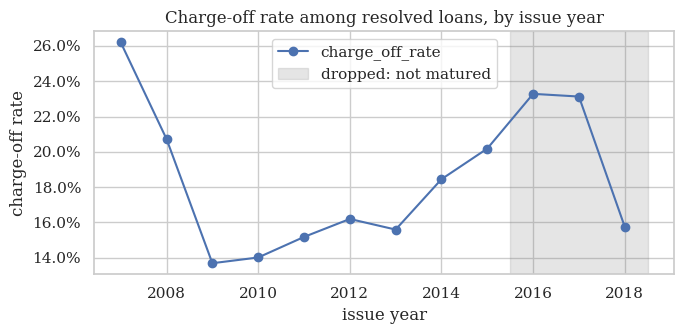

,charge_off_rate,n_resolved
issue_year,,
2007,0.2620,603
2008,0.2073,2393
2009,0.1369,5281
2010,0.1401,12537
2011,0.1518,21721
2012,0.1620,53367
2013,0.1560,134804
2014,0.1845,223103
2015,0.2019,375546


In [7]:
# Why the maturity filter matters: charge-off rate among *resolved* loans by vintage
by_year = resolved.groupby("issue_year")["target"].agg(["mean", "size"]).rename(columns={"mean": "charge_off_rate", "size": "n_resolved"})
ax = by_year["charge_off_rate"].plot(marker="o", figsize=(7, 3.5))
ax.axvspan(2015.5, by_year.index.max() + 0.5, color="grey", alpha=0.2, label="dropped: not matured")
ax.set(title="Charge-off rate among resolved loans, by issue year", ylabel="charge-off rate", xlabel="issue year")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.legend()
plt.tight_layout(); plt.show()
by_year

## 4. Modeling sample and the shared train/test split

A stratified sample of `N_MODEL` loans keeps SVM and random-forest runtimes practical. The split is made **once**, here, stratified on the target with a fixed seed, and saved. Every later notebook uses these exact rows, and the test rows are never used for tuning.

In [8]:
if len(clean) > N_MODEL:
    sample, _ = train_test_split(clean, train_size=N_MODEL, stratify=clean["target"], random_state=RANDOM_STATE)
else:
    sample = clean
train_idx, test_idx = train_test_split(sample.index, test_size=TEST_SIZE, stratify=sample["target"], random_state=RANDOM_STATE)
sample = sample.copy()
sample["split"] = "train"
sample.loc[test_idx, "split"] = "test"
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
sample.to_parquet(OUT_PATH, index=False)
print(f"Saved {OUT_PATH}: {len(sample):,} rows | train {len(train_idx):,} | test {len(test_idx):,}")
sample.groupby("split")["target"].mean().rename("charge_off_rate").to_frame()

Saved data/lc_model_sample.parquet: 200,000 rows | train 140,000 | test 60,000


,charge_off_rate
split,
test,0.1487
train,0.1487


## 5. Exploratory data analysis

The EDA uses the training rows only, so nothing about the test set influences modeling decisions.

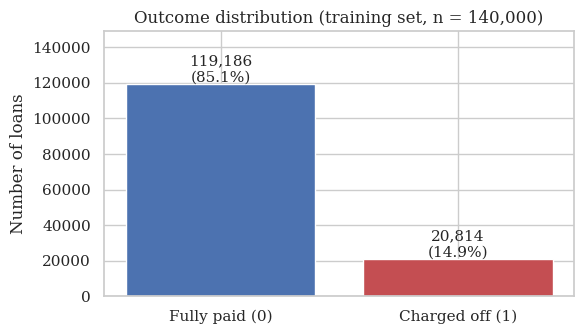

In [9]:
train = sample[sample["split"] == "train"].copy()
test = sample[sample["split"] == "test"].copy()

# Figure 1 for the report: outcome distribution
counts = train["target"].map({0: "Fully paid (0)", 1: "Charged off (1)"}).value_counts()
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v/counts.sum():.1%})", ha="center", va="bottom", fontsize=11)
ax.set(ylabel="Number of loans", title=f"Outcome distribution (training set, n = {counts.sum():,})")
ax.set_ylim(0, counts.max() * 1.25)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_outcome_distribution.png", dpi=200); plt.show()

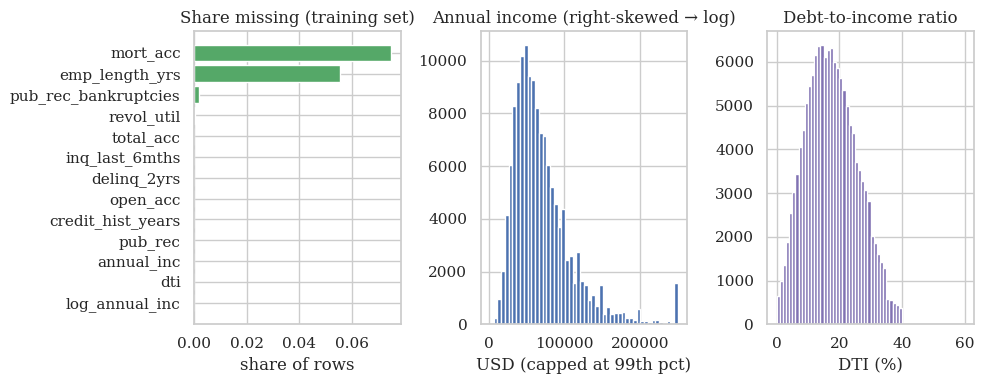

Missing shares:
 mort_acc               0.0746
emp_length_yrs         0.0555
pub_rec_bankruptcies   0.0020
revol_util             0.0006
total_acc              0.0000
inq_last_6mths         0.0000
delinq_2yrs            0.0000
open_acc               0.0000
credit_hist_years      0.0000
pub_rec                0.0000
annual_inc             0.0000
dti                    0.0000
log_annual_inc         0.0000


In [10]:
# Figure 2 for the report: missingness + two distributions that drove cleaning decisions
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
miss = train.drop(columns=["target", "split"]).isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
axes[0].barh(miss.index[::-1], miss.values[::-1], color="#55A868")
axes[0].set(title="Share missing (training set)", xlabel="share of rows")
axes[1].hist(train["annual_inc"].clip(upper=train["annual_inc"].quantile(0.99)), bins=50, color="#4C72B0")
axes[1].set(title="Annual income (right-skewed → log)", xlabel="USD (capped at 99th pct)")
axes[2].hist(train["dti"].clip(-1, 60), bins=60, color="#8172B2")
axes[2].set(title="Debt-to-income ratio", xlabel="DTI (%)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_missingness_distributions.png", dpi=200); plt.show()
print("Missing shares:\n", miss.round(4).to_string())

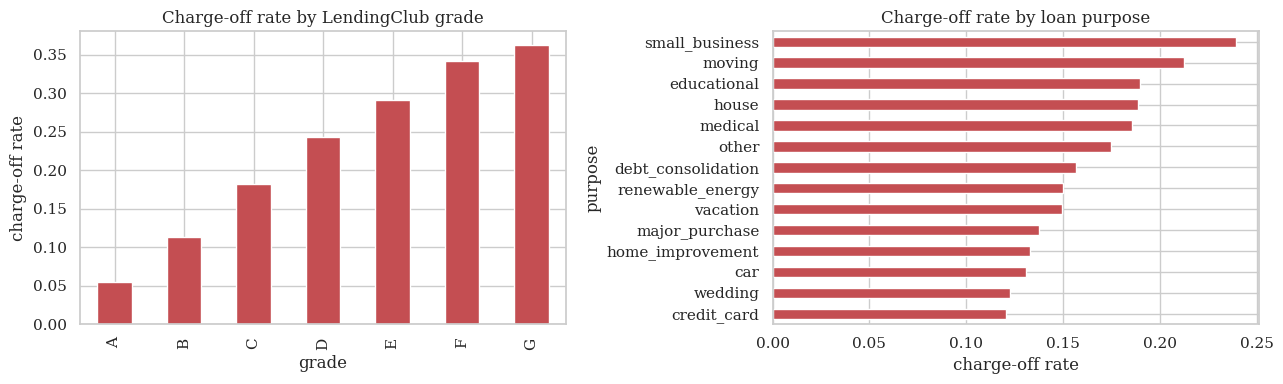

In [11]:
# Charge-off rate by grade and by purpose (EDA for Weeks 4-6)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train.groupby("grade")["target"].mean().plot.bar(ax=axes[0], color="#C44E52")
axes[0].set(title="Charge-off rate by LendingClub grade", ylabel="charge-off rate")
train.groupby("purpose")["target"].mean().sort_values().plot.barh(ax=axes[1], color="#C44E52")
axes[1].set(title="Charge-off rate by loan purpose", xlabel="charge-off rate")
plt.tight_layout(); plt.show()

## 6. Week 1 regression: what drives the interest rate?

**Target:** `int_rate` (%).
**Excluded predictors:** `grade` and `sub_grade` (LendingClub sets the rate *from* the sub-grade, so including them makes the regression nearly trivial; see Section 9) and `installment` (a deterministic function of loan amount, term, **and the interest rate itself**, so it leaks the target).

In [12]:
NUM = ["loan_amnt", "log_annual_inc", "dti", "fico", "inq_last_6mths", "delinq_2yrs", "open_acc",
       "total_acc", "revol_util", "log_revol_bal", "pub_rec", "mort_acc", "pub_rec_bankruptcies",
       "credit_hist_years", "emp_length_yrs", "ever_delinq"]
CAT = ["term", "home_ownership", "verification_status", "purpose", "application_type", "initial_list_status"]

def impute(train_df, other_dfs, min_share=0.005):
    """Imputation and rare-level grouping learned on training rows only.
    Numeric: training median. Categorical: 'Missing' level; levels with <0.5% of training rows -> 'Other'."""
    med = train_df[NUM].median()
    keep = {}
    for c in CAT:
        share = train_df[c].astype("string").fillna("Missing").value_counts(normalize=True)
        keep[c] = set(share[share >= min_share].index)
    out = []
    for d in [train_df] + other_dfs:
        d = d.copy()
        d[NUM] = d[NUM].fillna(med)
        for c in CAT:
            v = d[c].astype("string").fillna("Missing").astype(str)
            d[c] = v.where(v.isin(keep[c]), "Other")
        out.append(d)
    return out

tr, te = impute(train, [test])
CAT = [c for c in CAT if tr[c].nunique() > 1]   # drop categoricals with a single level in this sample
print("Categorical predictors used:", CAT)
tr[["int_rate"] + NUM].describe().T

Categorical predictors used: ['term', 'home_ownership', 'verification_status', 'purpose', 'application_type', 'initial_list_status']


,count,mean,std,min,25%,50%,75%,max
int_rate,"140,000.0000",12.4474,4.1334,5.3200,9.1700,12.2900,14.9900,28.4900
loan_amnt,"140,000.0000","13,075.2991","8,021.4807",500.0000,"7,000.0000","11,000.0000","18,000.0000","35,000.0000"
log_annual_inc,"140,000.0000",11.0395,0.5438,7.4793,10.6920,11.0186,11.3851,15.9556
dti,"140,000.0000",17.5137,8.1776,0.0000,11.3700,17.0200,23.1925,60.0800
fico,"140,000.0000",697.4895,31.1798,627.0000,672.0000,692.0000,712.0000,847.5000
inq_last_6mths,"140,000.0000",0.7149,1.0120,0.0000,0.0000,0.0000,1.0000,24.0000
delinq_2yrs,"140,000.0000",0.3066,0.8521,0.0000,0.0000,0.0000,0.0000,30.0000
open_acc,"140,000.0000",11.2406,5.1879,0.0000,8.0000,10.0000,14.0000,62.0000
total_acc,"140,000.0000",24.6230,11.7471,1.0000,16.0000,23.0000,31.0000,156.0000
revol_util,"140,000.0000",54.1045,23.9405,0.0000,36.5000,54.9000,72.6000,177.7000


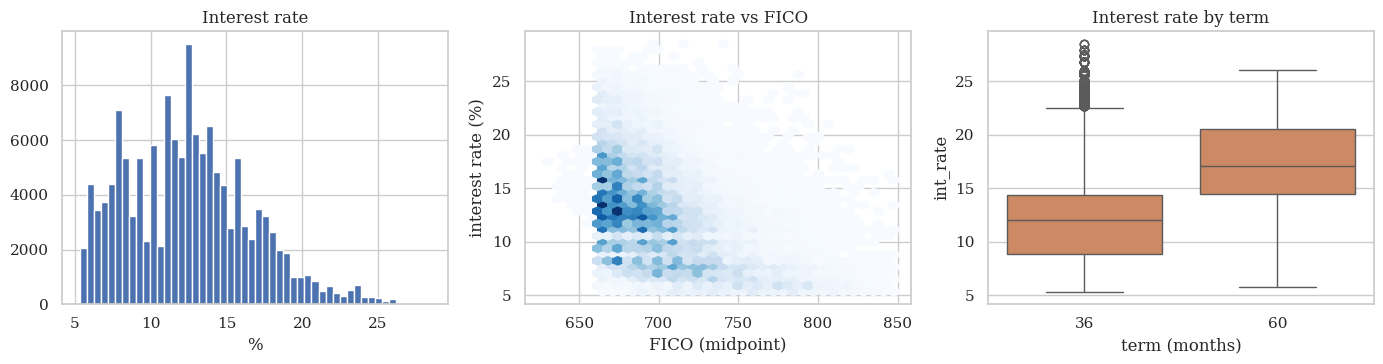

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(tr["int_rate"], bins=50, color="#4C72B0"); axes[0].set(title="Interest rate", xlabel="%")
hb = axes[1].hexbin(tr["fico"], tr["int_rate"], gridsize=35, cmap="Blues", mincnt=1)
axes[1].set(title="Interest rate vs FICO", xlabel="FICO (midpoint)", ylabel="interest rate (%)")
sns.boxplot(data=tr, x="term", y="int_rate", ax=axes[2], color="#DD8452")
axes[2].set(title="Interest rate by term", xlabel="term (months)")
plt.tight_layout(); plt.show()

## 7. Multicollinearity and the variance inflation factor

VIF for predictor *j* is $1/(1-R_j^2)$, where $R_j^2$ comes from regressing *j* on all other predictors. Values above about 5–10 signal that a coefficient's standard error is inflated by overlap with other predictors. Three checks:

1. the continuous predictors as used;
2. a demonstration of what happens if we add `installment` and both FICO bounds (the reason we dropped them);
3. polynomial terms with and without centering.

In [14]:
def vif_table(X):
    X = sm.add_constant(X.astype(float), has_constant="add")
    v = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return pd.Series(v, index=X.columns).drop("const").sort_values(ascending=False).to_frame("VIF")

vif_used = vif_table(tr[NUM])
vif_used

,VIF
total_acc,2.5021
open_acc,2.3782
revol_util,1.9847
fico,1.8665
log_revol_bal,1.8459
log_annual_inc,1.8415
pub_rec_bankruptcies,1.8275
pub_rec,1.7287
loan_amnt,1.4964
ever_delinq,1.4224


In [15]:
demo = tr[NUM].copy()
demo["installment"] = train["installment"].values
demo["fico_low_demo"] = demo["fico"] - 2   # reconstructing the dropped bounds
demo["fico_high_demo"] = demo["fico"] + 2
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # perfect collinearity -> infinite VIF
    vif_demo = vif_table(demo).head(6)
vif_demo

,VIF
fico_high_demo,inf
fico,inf
fico_low_demo,inf
loan_amnt,25.8090
installment,24.9180
total_acc,2.5097


**Reading the table:** FICO low and high are perfectly collinear (VIF = ∞), which is why we use their midpoint. `installment` is largely determined by `loan_amnt` (and term and rate), so its VIF and `loan_amnt`'s jump together.

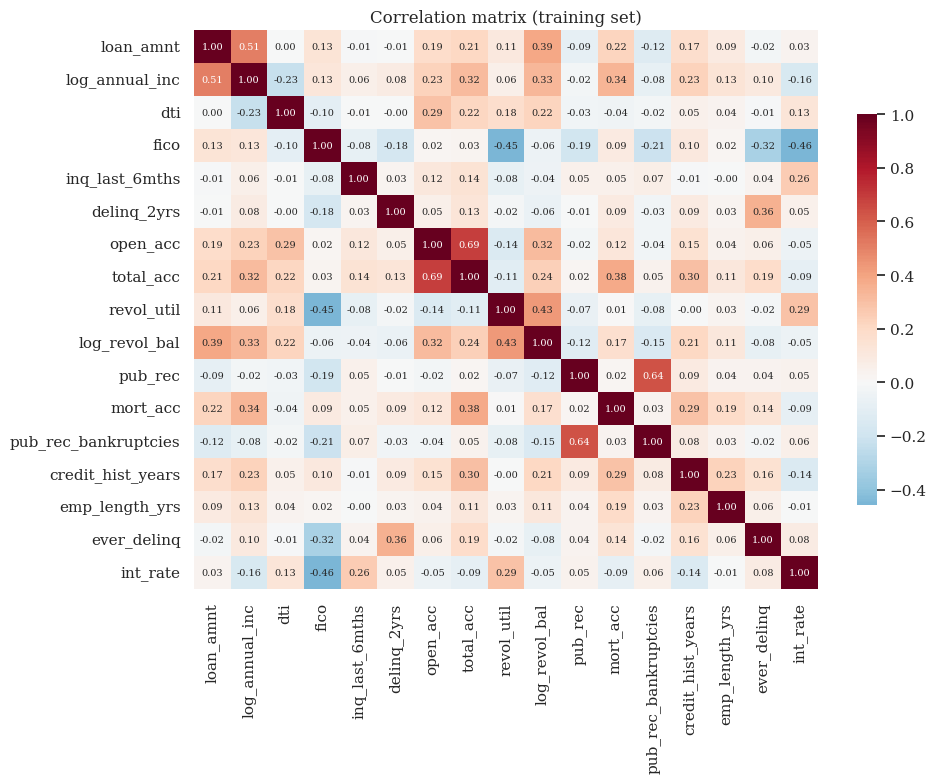

In [16]:
corr = tr[NUM + ["int_rate"]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"shrink": .7})
plt.title("Correlation matrix (training set)"); plt.tight_layout(); plt.show()

## 8. Models: continuous → + categorical → + polynomial & interaction terms

* **M1:** continuous predictors only
* **M2:** M1 + categorical predictors (dummy-coded with `C()`; the first level is the reference)
* **M3:** M2 + quadratic terms for FICO and DTI, and interactions **term × FICO** and **term × DTI** (does a borrower's credit profile matter differently for 36- vs 60-month loans?)

The quadratic and interaction terms use **centered** FICO and DTI. Centering lowers the collinearity between *x* and *x²* without changing the fitted values.

In [17]:
for d in (tr, te):
    d["fico_c"] = d["fico"] - tr["fico"].mean()
    d["dti_c"] = d["dti"] - tr["dti"].mean()

num_terms = " + ".join(NUM)
num_terms_c = " + ".join({"fico": "fico_c", "dti": "dti_c"}.get(c, c) for c in NUM)  # same fit, centered
cat_terms = " + ".join(f"C({c})" for c in CAT)
F = {
    "M1 continuous": f"int_rate ~ {num_terms}",
    "M2 + categorical": f"int_rate ~ {num_terms} + {cat_terms}",
    # C(term)*fico_c expands to C(term) + fico_c + C(term):fico_c (60-month slope difference)
    "M3 + poly & interactions": f"int_rate ~ {num_terms_c} + {cat_terms} + I(fico_c**2) + I(dti_c**2)"
                                 " + C(term)*fico_c + C(term)*dti_c",
}

def cv_rmse(formula, data, k=5):
    errs = []
    for a, b in KFold(k, shuffle=True, random_state=RANDOM_STATE).split(data):
        m = smf.ols(formula, data.iloc[a]).fit()
        errs.append(np.sqrt(np.mean((data.iloc[b]["int_rate"] - m.predict(data.iloc[b])) ** 2)))
    return np.mean(errs)

fits, rows = {}, []
for name, f in F.items():
    m = smf.ols(f, tr).fit()
    fits[name] = m
    rows.append({"model": name, "n_params": int(m.df_model) + 1, "adj_R2": m.rsquared_adj, "AIC": m.aic,
                 "CV_RMSE (train, 5-fold)": cv_rmse(f, tr),
                 "test_RMSE": np.sqrt(np.mean((te["int_rate"] - m.predict(te)) ** 2))})
week1_results = pd.DataFrame(rows).set_index("model")
week1_results

,n_params,adj_R2,AIC,"CV_RMSE (train, 5-fold)",test_RMSE
model,,,,,
M1 continuous,17,0.3526,"733,794.6457",3.3263,3.3410
M2 + categorical,35,0.5268,"689,926.1262",2.8441,2.8572
M3 + poly & interactions,39,0.5367,"686,987.9247",2.8144,2.8247


In [18]:
# Nested-model F-tests: does each block of terms add explanatory power?
anova_lm(fits["M1 continuous"], fits["M2 + categorical"], fits["M3 + poly & interactions"])

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,"139,983.0000","1,548,299.9873",0.0000,NaN,NaN,NaN
1,"139,965.0000","1,131,510.9187",18.0000,"416,789.0685","2,925.0381",0.0000
2,"139,961.0000","1,107,947.8710",4.0000,"23,563.0478",744.1478,0.0000


In [19]:
m3 = fits["M3 + poly & interactions"]
coefs = pd.DataFrame({"coef": m3.params, "std_err": m3.bse, "p_value": m3.pvalues})
coefs.loc[[i for i in coefs.index if ("fico" in i or "dti" in i or "term" in i)]]

,coef,std_err,p_value
C(term)[T.60],4.5823,0.0299,0.0000
dti_c,0.0329,0.0012,0.0000
C(term)[T.60]:dti_c,0.0100,0.0038,0.0081
fico_c,-0.0578,0.0004,0.0000
C(term)[T.60]:fico_c,-0.0293,0.0009,0.0000
I(fico_c ** 2),0.0002,0.0000,0.0000
I(dti_c ** 2),0.0024,0.0001,0.0000


In [20]:
# VIF: raw vs centered polynomial terms
poly_raw = tr[["fico", "dti"]].assign(fico_sq=tr["fico"] ** 2, dti_sq=tr["dti"] ** 2)
poly_cen = tr[["fico_c", "dti_c"]].assign(fico_c_sq=tr["fico_c"] ** 2, dti_c_sq=tr["dti_c"] ** 2)
v_raw = vif_table(poly_raw)["VIF"]
v_cen = vif_table(poly_cen)["VIF"].rename(lambda c: c.replace("_c", ""))
pd.DataFrame({"VIF raw": v_raw, "VIF centered": v_cen}).loc[["fico", "dti", "fico_sq", "dti_sq"]]

,VIF raw,VIF centered
fico,"1,046.2287",1.8140
dti,15.6069,1.0690
fico_sq,"1,046.9905",1.8343
dti_sq,15.5164,1.0531


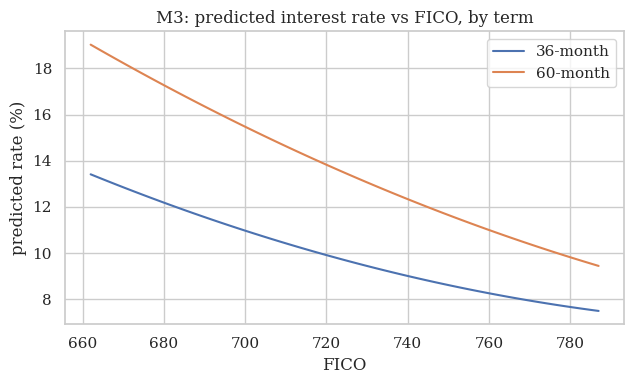

In [21]:
# Visualizing the interaction: predicted rate vs FICO for 36- vs 60-month loans (others at typical values)
grid = pd.DataFrame({"fico": np.linspace(tr["fico"].quantile(.02), tr["fico"].quantile(.98), 60)})
base = tr.mode().iloc[0]
for c in NUM: base[c] = tr[c].median()
fig, ax = plt.subplots(figsize=(6.5, 4))
for t in sorted(tr["term"].unique()):
    g = pd.DataFrame([base] * len(grid)).reset_index(drop=True).infer_objects()
    g["fico"] = grid["fico"]; g["term"] = t
    g["fico_c"] = g["fico"] - tr["fico"].mean(); g["dti_c"] = g["dti"] - tr["dti"].mean()
    ax.plot(g["fico"], m3.predict(g), label=f"{t}-month")
ax.set(title="M3: predicted interest rate vs FICO, by term", xlabel="FICO", ylabel="predicted rate (%)"); ax.legend()
plt.tight_layout(); plt.show()

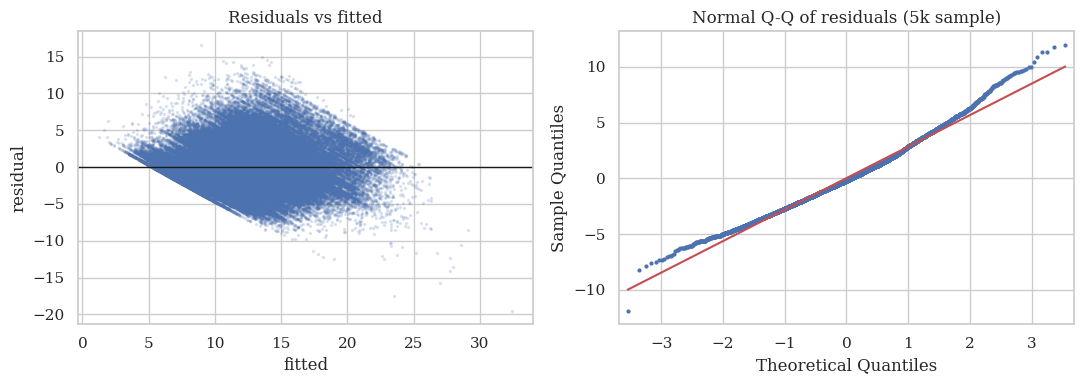

In [22]:
# Residual diagnostics for M3
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(m3.fittedvalues, m3.resid, s=2, alpha=0.15); axes[0].axhline(0, color="k", lw=1)
axes[0].set(title="Residuals vs fitted", xlabel="fitted", ylabel="residual")
sm.qqplot(m3.resid.sample(min(5000, len(m3.resid)), random_state=RANDOM_STATE), line="s", ax=axes[1], markersize=2)
axes[1].set_title("Normal Q-Q of residuals (5k sample)")
plt.tight_layout(); plt.show()

## 9. Why grade was excluded

Adding `sub_grade` shows how much of the rate is LendingClub's own grade.

In [23]:
tr["sub_grade"] = train["sub_grade"].values
m_grade = smf.ols("int_rate ~ C(sub_grade)", tr).fit()
print(f"R² from sub_grade alone: {m_grade.rsquared:.3f}  vs  M3 R²: {m3.rsquared:.3f}")

R² from sub_grade alone: 0.950  vs  M3 R²: 0.537


## 10. Numbers for the Milestone report

In [24]:
report = {
    "raw rows x cols": f"{n_rows_raw:,} x {len(miss_all)}" if RUN_FULL_MISSINGNESS_SCAN else "run scan",
    "columns >50% missing (raw file)": int((miss_all > 0.5).sum()) if RUN_FULL_MISSINGNESS_SCAN else "run scan",
    "duplicate ids (removed)": n_dup_ids,
    "modeling population (resolved + matured)": f"{len(clean):,}",
    "charge-off rate (population)": f"{clean['target'].mean():.2%}",
    "modeling sample / train / test": f"{len(sample):,} / {len(train):,} / {len(test):,}",
    "issue date range": f"{clean['issue_d'].min():%b %Y} – {clean['issue_d'].max():%b %Y}",
}
pd.Series(report).to_frame("value")

,value
raw rows x cols,"2,260,701 x 151"
columns >50% missing (raw file),44
duplicate ids (removed),0
modeling population (resolved + matured),"676,302"
charge-off rate (population),14.87%
modeling sample / train / test,"200,000 / 140,000 / 60,000"
issue date range,Jun 2007 – Dec 2015


## 11. Conclusions

**Categorical vs. continuous.** Adding the categorical predictors (M1 → M2) was the biggest improvement: test RMSE fell from 3.341 to 2.857 and adjusted R² rose from 0.353 to 0.527. The 60-month term matters most, adding about 4.6 percentage points to the rate, holding the other predictors fixed.

**Polynomial and interaction terms.** M3 beats M2 on held-out error, not just adjusted R², but only slightly: test RMSE 2.825 vs. 2.857 and adjusted R² 0.537 vs. 0.527 (nested F-test p < .001). The term × FICO interaction is real: each FICO point lowers the rate by about 0.029 points more for 60-month loans than for 36-month loans, which shows as a steeper line in the interaction plot. M3's CV RMSE (2.814) is close to its test RMSE (2.825), so the extra terms do not overfit. Before DTI values outside 0–100 were treated as missing, one loan with DTI = 999 had inflated M3's CV RMSE to 5.20.

**Multicollinearity.** No predictor in the model has VIF above 5; the largest is total_acc at 2.5. The demonstration shows why two fields were dropped: the FICO low/high bounds are perfectly collinear (VIF = ∞), and installment has VIF ≈ 25 with loan amount. Raw FICO and FICO² have VIF ≈ 1,047; centering brings both to about 1.8 without changing the fitted values, so the linear and squared FICO coefficients can be interpreted separately.

**Grade.** Sub-grade alone explains R² = 0.950 of the rate, against 0.537 for M3. LendingClub prices almost entirely by its own grade, which is why `int_rate` and `grade` in the Weeks 4–6 charge-off models partly reproduce the lender's own risk assessment.

**EDA → modeling decisions.** This notebook produced the log transforms of income and revolving balance, the `ever_delinq` flag, the FICO midpoint, the DTI placeholder rule, the exclusion of `installment`, and the maturity filter. That filter matters: among resolved loans, 2016–2017 vintages show charge-off rates above 23% only because early defaults resolve first.
